# **LSTM MODEL**

d:\final4-2 project\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
4119/4119 - 48s - 12ms/step - loss: 0.6493 - val_loss: 0.6046
Epoch 2/20
4119/4119 - 47s - 11ms/step - loss: 0.6074 - val_loss: 0.5659
Epoch 3/20
4119/4119 - 47s - 11ms/step - loss: 0.5829 - val_loss: 0.5363
Epoch 4/20
4119/4119 - 48s - 12ms/step - loss: 0.5636 - val_loss: 0.5112
Epoch 5/20
4119/4119 - 46s - 11ms/step - loss: 0.5473 - val_loss: 0.4899
Epoch 6/20
4119/4119 - 47s - 11ms/step - loss: 0.5330 - val_loss: 0.4714
Epoch 7/20
4119/4119 - 47s - 11ms/step - loss: 0.5196 - val_loss: 0.4553
Epoch 8/20
4119/4119 - 47s - 11ms/step - loss: 0.5078 - val_loss: 0.4418
Epoch 9/20
4119/4119 - 47s - 11ms/step - loss: 0.4974 - val_loss: 0.4303
Epoch 10/20
4119/4119 - 47s - 11ms/step - loss: 0.4883 - val_loss: 0.4207
Epoch 11/20
4119/4119 - 47s - 11ms/step - loss: 0.4799 - val_loss: 0.4111
Epoch 12/20
4119/4119 - 47s - 11ms/step - loss: 0.4722 - val_loss: 0.4035
Epoch 13/20
4119/4119 - 46s - 11ms/step - loss: 0.4650 - val_loss: 0.3951
Epoch 14/20
4119/4119 - 45s - 11ms/step - loss:

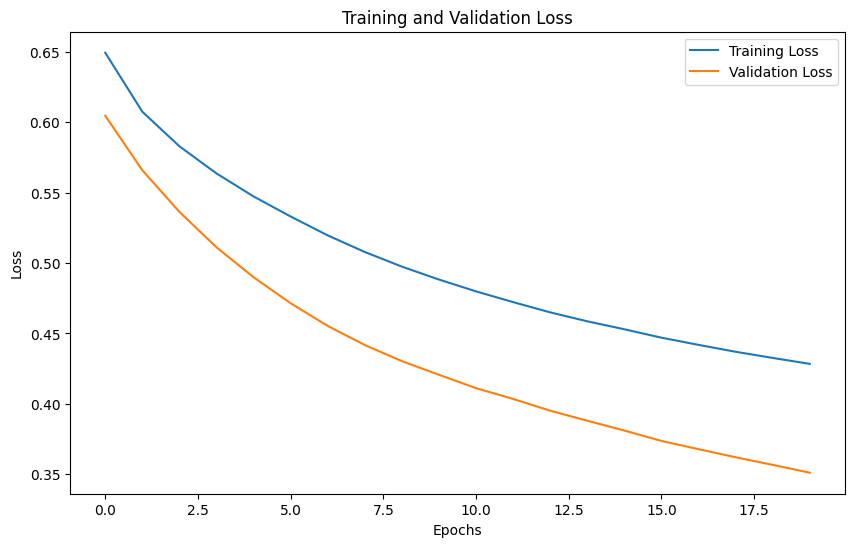

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from keras.models import Sequential
from keras.layers import LSTM, Dense, Dropout
from keras.callbacks import EarlyStopping
from keras.regularizers import l2

data = pd.read_csv("data/Features.csv")

X = data.drop(columns=['Class_Label', 'Date', 'User', 'Unnamed: 0'], axis=1)
y = data['Class_Label']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_temp, y_train, y_temp = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)
X_val_resampled, y_val_resampled = smote.fit_resample(X_val, y_val)

model = Sequential()
model.add(LSTM(32, input_shape=(X_train_resampled.shape[1], 1), kernel_regularizer=l2(0.001)))
model.add(Dropout(0.7))
model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy', optimizer='adagrad')

early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    X_train_resampled, y_train_resampled,
    epochs=20, batch_size=128,
    validation_data=(X_val_resampled, y_val_resampled),
    callbacks=[early_stopping],
    verbose=2
)

train_loss = history.history['loss']
val_loss = history.history['val_loss']

for epoch in range(len(train_loss)):
    print(f"Epoch {epoch + 1}/{len(train_loss)} - "
          f"Train Loss: {train_loss[epoch]:.4f} - "
          f"Validation Loss: {val_loss[epoch]:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()


d:\final4-2 project\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
2066/2066 - 28s - 14ms/step - accuracy: 0.8217 - loss: 0.4940 - val_accuracy: 0.8680 - val_loss: 0.3970
Epoch 2/20
2066/2066 - 24s - 12ms/step - accuracy: 0.8664 - loss: 0.3606 - val_accuracy: 0.8637 - val_loss: 0.3424
Epoch 3/20
2066/2066 - 25s - 12ms/step - accuracy: 0.8662 - loss: 0.3439 - val_accuracy: 0.8629 - val_loss: 0.4202
Epoch 4/20
2066/2066 - 25s - 12ms/step - accuracy: 0.8674 - loss: 0.3318 - val_accuracy: 0.8809 - val_loss: 0.2774
Epoch 5/20
2066/2066 - 25s - 12ms/step - accuracy: 0.8745 - loss: 0.3211 - val_accuracy: 0.8733 - val_loss: 0.2994
Epoch 6/20
2066/2066 - 25s - 12ms/step - accuracy: 0.8786 - loss: 0.3106 - val_accuracy: 0.8751 - val_loss: 0.3315
Epoch 7/20
2066/2066 - 25s - 12ms/step - accuracy: 0.8821 - loss: 0.3020 - val_accuracy: 0.8874 - val_loss: 0.2709
Epoch 8/20
2066/2066 - 25s - 12ms/step - accuracy: 0.8883 - loss: 0.2958 - val_accuracy: 0.8840 - val_loss: 0.2887
Epoch 9/20
2066/2066 - 25s - 12ms/step - accuracy: 0.8939 - loss: 0.2904 - val_a

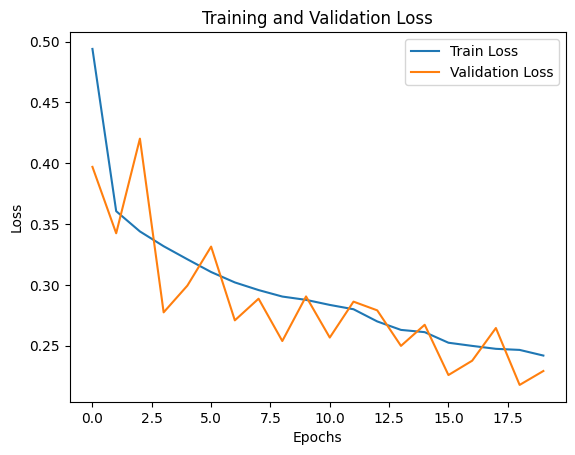

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

from keras.models import Sequential
from keras.layers import LSTM, Dense, Dropout
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam


data = pd.read_csv('Features.csv')

X = data.drop(columns=['Class_Label', 'Date', 'User', 'Unnamed: 0'], axis=1)
y = data['Class_Label']

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)


class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weight_dict = {
    0: class_weights[0],
    1: class_weights[1]
}


X_train = X_train.reshape(
    X_train.shape[0],
    X_train.shape[1],
    1
)

X_val = X_val.reshape(
    X_val.shape[0],
    X_val.shape[1],
    1
)


model = Sequential()
model.add(LSTM(32, input_shape=(X_train.shape[1], 1)))
model.add(Dropout(0.4))
model.add(Dense(1, activation='sigmoid'))

model.compile(
    loss='binary_crossentropy',
    optimizer=Adam(),
    metrics=['accuracy']
)


early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)


history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=128,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict,
    callbacks=[early_stopping],
    verbose=2
)


plt.figure()
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend(['Train Loss', 'Validation Loss'])
plt.show()

In [ ]:
import numpy as np


X_test = X_test.reshape(
    X_test.shape[0],
    X_test.shape[1],
    1
)



test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy (Keras): {test_acc * 100:.2f}%")

y_pred_prob = model.predict(X_test).flatten()


y_pred = (y_pred_prob >= 0.5).astype(int)


manual_accuracy = np.mean(y_pred == y_test)

print(f"Test Accuracy (Manual): {manual_accuracy * 100:.2f}%")

Test Loss: 0.2201
Test Accuracy (Keras): 92.52%
1033/1033 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step
Test Accuracy (Manual): 92.52%


Confusion Matrix:
[[30480  2467]
 [    6    93]]
Classification Report:
              precision    recall  f1-score   support

     Class 0       1.00      0.93      0.96     32947
     Class 1       0.04      0.94      0.07        99

    accuracy                           0.93     33046
   macro avg       0.52      0.93      0.52     33046
weighted avg       1.00      0.93      0.96     33046



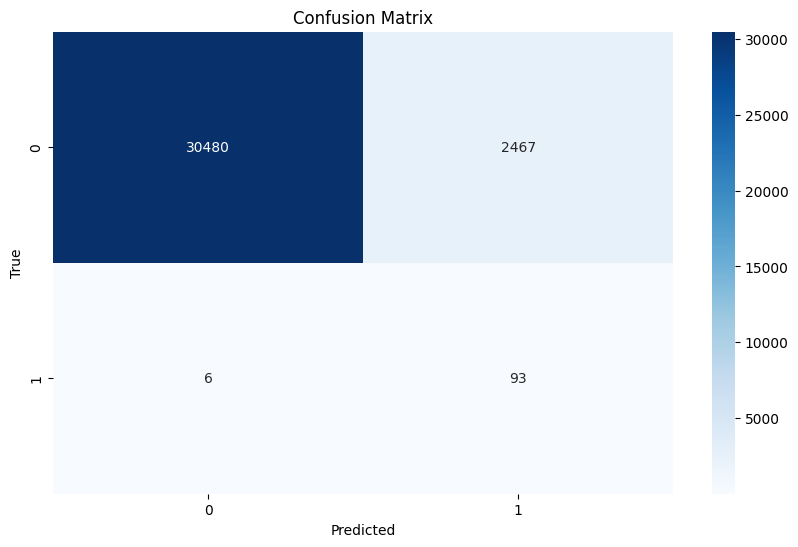

In [6]:

# Calculate the confusion matrix and classification report
from sklearn.metrics import confusion_matrix, classification_report

confusion = confusion_matrix(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred, target_names=['Class 0', 'Class 1'])

# Print the confusion matrix
print("Confusion Matrix:")
print(confusion)

# Print the classification report
print("Classification Report:")
print(classification_rep)

# Plot the confusion matrix
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues", xticklabels=['0', '1'], yticklabels=['0', '1'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()


## **CNN Model**

Epoch 1/10


d:\final4-2 project\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


14827/14827 ━━━━━━━━━━━━━━━━━━━━ 139s 9ms/step - accuracy: 0.9491 - loss: 0.1462 - val_accuracy: 0.9774 - val_loss: 0.0758
Epoch 2/10
14827/14827 ━━━━━━━━━━━━━━━━━━━━ 138s 9ms/step - accuracy: 0.9742 - loss: 0.0800 - val_accuracy: 0.9748 - val_loss: 0.0741
Epoch 3/10
14827/14827 ━━━━━━━━━━━━━━━━━━━━ 139s 9ms/step - accuracy: 0.9812 - loss: 0.0611 - val_accuracy: 0.9953 - val_loss: 0.0221
Epoch 4/10
14827/14827 ━━━━━━━━━━━━━━━━━━━━ 121s 8ms/step - accuracy: 0.9848 - loss: 0.0502 - val_accuracy: 0.9934 - val_loss: 0.0285
Epoch 5/10
14827/14827 ━━━━━━━━━━━━━━━━━━━━ 121s 8ms/step - accuracy: 0.9868 - loss: 0.0438 - val_accuracy: 0.9898 - val_loss: 0.0392
Epoch 6/10
14827/14827 ━━━━━━━━━━━━━━━━━━━━ 123s 8ms/step - accuracy: 0.9884 - loss: 0.0393 - val_accuracy: 0.9949 - val_loss: 0.0227
Epoch 7/10
14827/14827 ━━━━━━━━━━━━━━━━━━━━ 122s 8ms/step - accuracy: 0.9895 - loss: 0.0357 - val_accuracy: 0.9964 - val_loss: 0.0163
Epoch 8/10
14827/14827 ━━━━━━━━━━━━━━━━━━━━ 122s 8ms/step - accuracy: 0.9

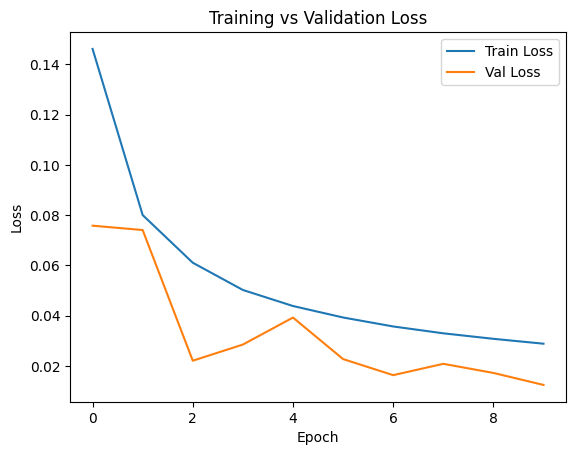

2066/2066 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step


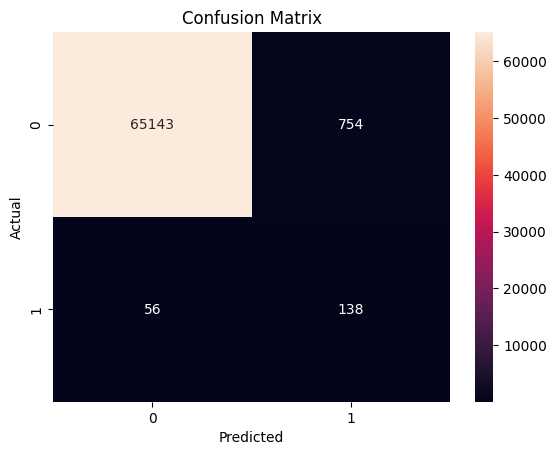

Classification Report:

              precision    recall  f1-score   support

         0.0       1.00      0.99      0.99     65897
         1.0       0.15      0.71      0.25       194

    accuracy                           0.99     66091
   macro avg       0.58      0.85      0.62     66091
weighted avg       1.00      0.99      0.99     66091



In [7]:
import tensorflow as tf
from tensorflow import keras
from keras.layers import Conv1D, Flatten, Dense, Dropout
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sn
import matplotlib.pyplot as plt

# Load dataset
data = pd.read_csv('Features.csv')  # change path if using VS Code
data.drop(['Unnamed: 0', 'Date', 'User'], axis=1, inplace=True)

# Features and target
X = data.drop('Class_Label', axis=1).values
y = data['Class_Label'].values

# Train-test split FIRST (avoid data leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Apply SMOTE ONLY on training data
smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

# Reshape for Conv1D (samples, timesteps, channels)
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# CNN Model
model = keras.Sequential([
    Conv1D(32, 5, activation='relu', input_shape=(X_train.shape[1], 1)),
    Conv1D(64, 3, activation='relu'),
    Conv1D(64, 5, activation='relu'),
    Conv1D(32, 3, activation='relu'),
    Flatten(),
    Dropout(0.1),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(
    X_train, y_train,
    epochs=10,
    validation_split=0.1,
    batch_size=32
)

# Plot loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()

# Predictions
y_pred = model.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_classes)
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
print("Classification Report:\n")
print(classification_report(y_test, y_pred_classes))


d:\final4-2 project\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
14827/14827 ━━━━━━━━━━━━━━━━━━━━ 102s 7ms/step - accuracy: 0.9567 - loss: 0.1253 - val_accuracy: 0.9892 - val_loss: 0.0442
Epoch 2/15
14827/14827 ━━━━━━━━━━━━━━━━━━━━ 430s 29ms/step - accuracy: 0.9752 - loss: 0.0760 - val_accuracy: 0.9976 - val_loss: 0.0177
Epoch 3/15
14827/14827 ━━━━━━━━━━━━━━━━━━━━ 77s 5ms/step - accuracy: 0.9802 - loss: 0.0631 - val_accuracy: 0.9953 - val_loss: 0.0267
Epoch 4/15
14827/14827 ━━━━━━━━━━━━━━━━━━━━ 78s 5ms/step - accuracy: 0.9828 - loss: 0.0556 - val_accuracy: 0.9981 - val_loss: 0.0125
Epoch 5/15
14827/14827 ━━━━━━━━━━━━━━━━━━━━ 80s 5ms/step - accuracy: 0.9844 - loss: 0.0511 - val_accuracy: 0.9980 - val_loss: 0.0131
Epoch 6/15
14827/14827 ━━━━━━━━━━━━━━━━━━━━ 82s 6ms/step - accuracy: 0.9858 - loss: 0.0470 - val_accuracy: 0.9991 - val_loss: 0.0102
Epoch 7/15
14827/14827 ━━━━━━━━━━━━━━━━━━━━ 81s 5ms/step - accuracy: 0.9866 - loss: 0.0449 - val_accuracy: 0.9992 - val_loss: 0.0102
Epoch 8/15
14827/14827 ━━━━━━━━━━━━━━━━━━━━ 77s 5ms/step - accurac

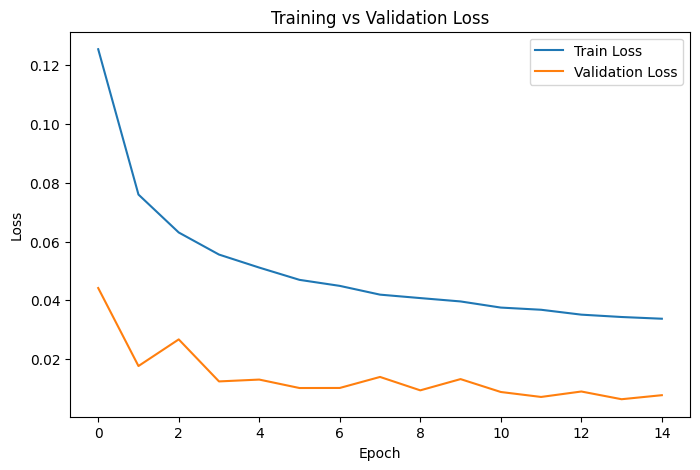

2066/2066 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


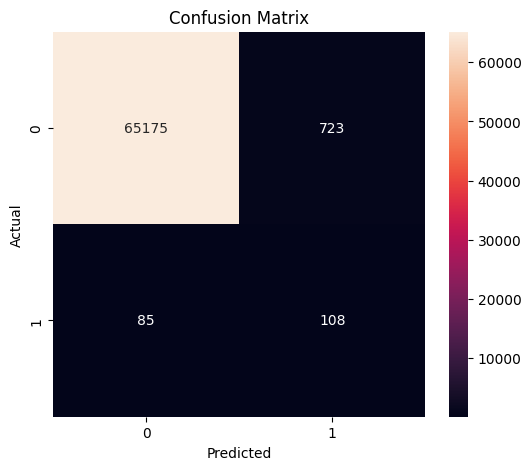


Classification Report:

              precision    recall  f1-score   support

         0.0       1.00      0.99      0.99     65898
         1.0       0.13      0.56      0.21       193

    accuracy                           0.99     66091
   macro avg       0.56      0.77      0.60     66091
weighted avg       1.00      0.99      0.99     66091



In [10]:
import tensorflow as tf
from tensorflow import keras
from keras.layers import Conv1D, Flatten, Dense, Dropout

import numpy as np
import pandas as pd

from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

import seaborn as sn
import matplotlib.pyplot as plt

data = pd.read_csv('Features.csv')

data.drop(['Unnamed: 0','Date','User'], axis=1, inplace=True)


X = data.drop('Class_Label', axis=1).values
y = data['Class_Label'].values


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

smote = SMOTE(random_state=42)

X_train, y_train = smote.fit_resample(X_train, y_train)

X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)



model = keras.Sequential([

    Conv1D(32, kernel_size=3, activation='relu',
           input_shape=(X_train.shape[1],1)),

    Conv1D(64, kernel_size=3, activation='relu'),

    Flatten(),

    Dropout(0.3),

    Dense(32, activation='relu'),

    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.1
)

plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()

plt.show()

y_pred_prob = model.predict(X_test)


threshold = 0.7

y_pred = (y_pred_prob >= threshold).astype(int)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sn.heatmap(cm, annot=True, fmt='d')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

2066/2066 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


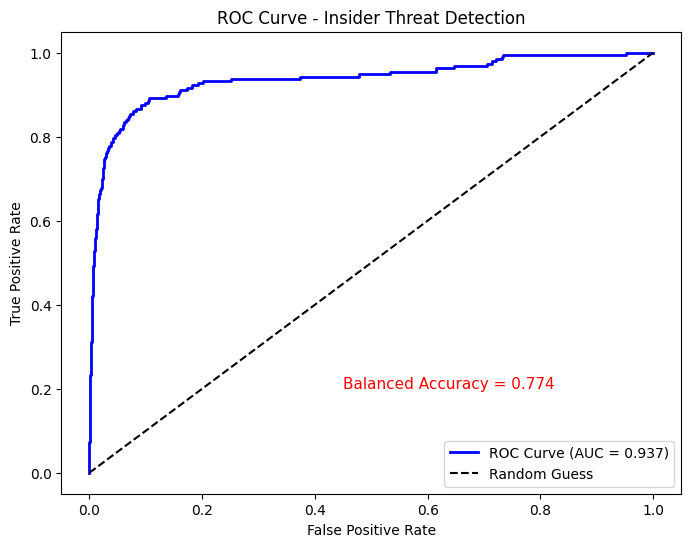

ROC-AUC Score: 0.9373367413322238
Balanced Accuracy: 0.7743069954083537


In [11]:
from sklearn.metrics import roc_curve, roc_auc_score, balanced_accuracy_score
import matplotlib.pyplot as plt
import numpy as np

y_pred_prob = model.predict(X_test).ravel()

threshold = 0.7

y_pred_class = (y_pred_prob >= threshold).astype(int)


fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

roc_auc = roc_auc_score(y_test, y_pred_prob)


balanced_acc = balanced_accuracy_score(y_test, y_pred_class)

plt.figure(figsize=(8,6))

plt.plot(fpr, tpr, color='blue', lw=2,
         label=f'ROC Curve (AUC = {roc_auc:.3f})')

plt.plot([0,1],[0,1],'k--', label="Random Guess")

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Insider Threat Detection')

plt.legend(loc='lower right')

plt.text(0.45,0.2,f'Balanced Accuracy = {balanced_acc:.3f}',
         fontsize=11, color='red')

plt.show()

print("ROC-AUC Score:", roc_auc)
print("Balanced Accuracy:", balanced_acc)

In [13]:
import pandas as pd

data = pd.read_csv('Features.csv')

threat_users = data[data['Class_Label'] == 1]

unique_users = threat_users[['User']].drop_duplicates()

unique_users.to_csv('threat_users_list.csv', index=False)
print("Total Threat Records:", len(threat_users))
print("Total Unique Threat Users:", len(unique_users))

print("\nThreat user list saved to: threat_users_list.csv")

Total Threat Records: 966
Total Unique Threat Users: 70

Threat user list saved to: threat_users_list.csv


In [14]:
threat_user_table = threat_users.groupby("User").size().reset_index(name="Threat_Events")

threat_user_table = threat_user_table.sort_values(by="Threat_Events", ascending=False)

print(threat_user_table)

       User  Threat_Events
51  MOS0047             35
2   ABC0174             33
31  HXL0968             32
58  PSF0133             30
13  CCL0068             30
..      ...            ...
7   BIH0745              1
27  GHL0460              1
17  DCH0843              1
41  KLH0596              1
57  PPF0435              1

[70 rows x 2 columns]


In [16]:
import pandas as pd
data = pd.read_csv('Features.csv')
threat_users = data[data['Class_Label'] == 1]
threat_summary = threat_users.groupby('User').size().reset_index(name='Threat_Events')
threat_summary.to_csv('threat_users_list.csv', index=False)
print("Total Threat Records:", len(threat_users))
print("Total Unique Threat Users:", len(threat_summary))

print("\nThreat users saved to: threat_users_list.csv")

Total Threat Records: 966
Total Unique Threat Users: 70

Threat users saved to: threat_users_list.csv
